In [1]:
pip install datasets

Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install datasets pandas matplotlib numpy torchvision

Note: you may need to restart the kernel to use updated packages.


In [11]:
from datasets import load_dataset

ds = load_dataset("Multimodal-Fatima/CUB_train", split='train')
print(ds)

Dataset({
    features: ['image', 'description', 'label', 'file_name', 'id'],
    num_rows: 5994
})


In [28]:
# 1. Load the Dataset
# Loading the default Hugging Face dataset specified in the project
dataset = load_dataset("Multimodal-Fatima/CUB_train", split="train")
df = dataset.to_pandas()
print(df.columns)

Index(['image', 'description', 'label', 'file_name', 'id'], dtype='str')


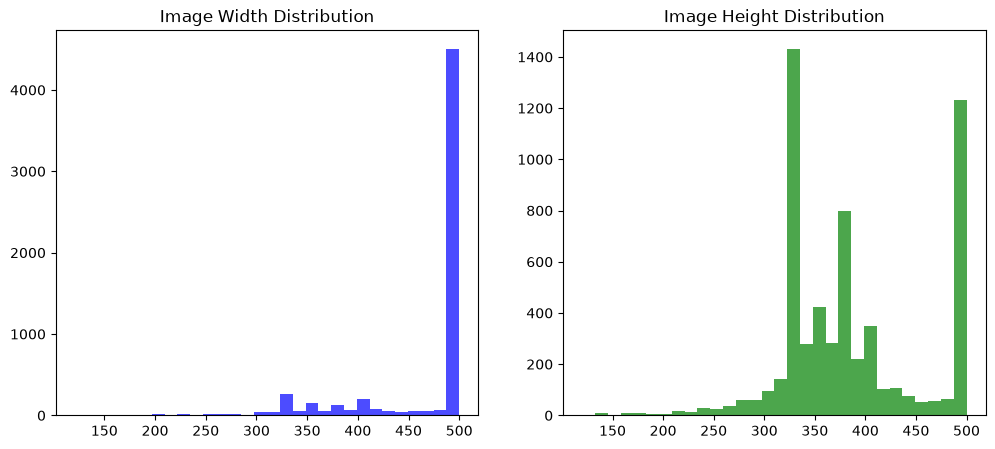

In [31]:
widths = [img.width for img in dataset['image']]
heights = [img.height for img in dataset['image']]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].hist(widths, bins=30, color='blue', alpha=0.7)
axes[0].set_title('Image Width Distribution')
axes[1].hist(heights, bins=30, color='green', alpha=0.7)
axes[1].set_title('Image Height Distribution')
plt.show()

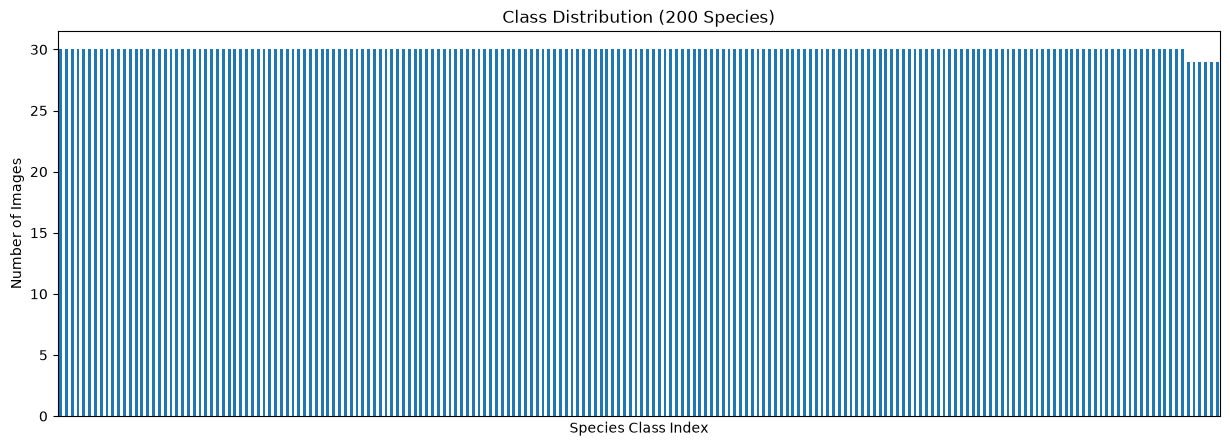

In [32]:
class_counts = df['label'].value_counts()
plt.figure(figsize=(15, 5))
class_counts.plot(kind='bar', xticks=[]) # Hiding xticks as 200 labels will crowd the axis
plt.title('Class Distribution (200 Species)')
plt.xlabel('Species Class Index')
plt.ylabel('Number of Images')
plt.show()

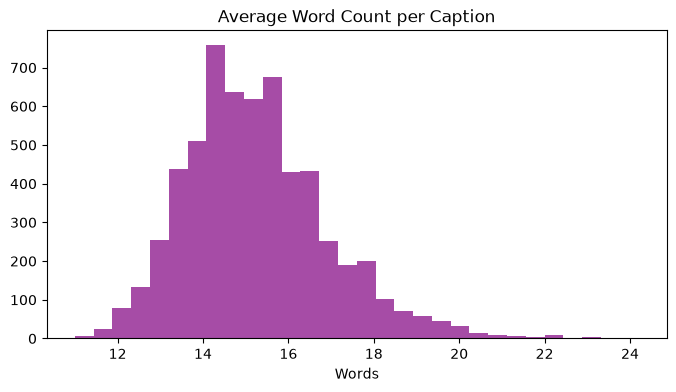

In [33]:
#The description field holds 10 captions separated by \n. We must split them.
df['parsed_captions'] = df['description'].apply(lambda x: x.strip().split('\n'))

# Calculate caption lengths to understand vocabulary and sequence modeling needs
df['avg_words_per_caption'] = df['parsed_captions'].apply(
    lambda caps: np.mean([len(c.split()) for c in caps])
)

plt.figure(figsize=(8, 4))
plt.hist(df['avg_words_per_caption'], bins=30, color='purple', alpha=0.7)
plt.title('Average Word Count per Caption')
plt.xlabel('Words')
plt.show()

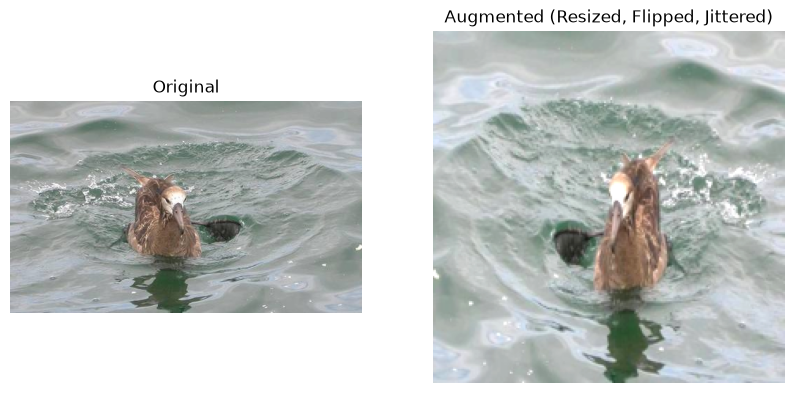

In [34]:
transform = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(p=1.0), # Forced to 1.0 just to visualize the change
    T.ColorJitter(brightness=0.2, contrast=0.2)
])

sample_img = dataset[0]['image']
aug_img = transform(sample_img)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
ax1.imshow(sample_img)
ax1.set_title("Original")
ax1.axis('off')
ax2.imshow(aug_img)
ax2.set_title("Augmented (Resized, Flipped, Jittered)")
ax2.axis('off')
plt.show()